# ELEC6604 作业 3 — 依次运行 CNN_A、CNN_B、CNN_C

在 Colab 中启用 GPU，然后从上到下运行，或选择“全部运行”。无需切换模型。
流程：共享配置和数据 → 定义模型及实验函数 → CNN_A → CNN_B → CNN_C → 汇总与下载。
每个模型使用三个随机种子，共九次训练。A、B 各训练 30 轮；C 最多训练 60 轮并允许早停。数据划分相同，但 C 的训练预算和策略不同，报告中需注明。
快速检查可将 `SEEDS = [42]`、`EPOCHS = 1`、`C_MAX_EPOCHS = 1`，正式实验请恢复默认值。
此版本已清空旧输出，避免把旧 CNN_C 结果误认为本次三模型结果；原有运行记录另存为备份 Notebook。

当前为 CNN_C 优化实验 5：仅将三个卷积块中的普通 Dropout 替换为 SpatialDropout2D，概率仍为 0.2／0.3／0.4。保留 Dense384 后的普通 Dropout(0.5)、L2=3e-4 和现有训练策略。参数量仍为 1,080,170。实验 4 的完整结果另存备份。


In [47]:
import os
import json
import time
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("No GPU detected. Enable a GPU runtime in Colab for faster training.")


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. 共享实验配置
三个模型共用数据划分、随机种子、批次大小、初始学习率和归一化方式。
`NORMALIZATION` 可设为 `zero_one`（[0,1]）或 `minus_one_one`（[-1,1]），用于后续归一化对照实验。
启用 `SAVE_TO_DRIVE` 可持久保存结果；否则结束 Colab 会话前请下载最终 ZIP。
每次重新运行配置单元格都会创建新的实验目录并重置汇总记录。中断后若运行时仍在，可直接重跑未完成模型的单元格，无需重跑配置和已完成模型。

CNN_C 的验证 loss 连续 3 轮未改善时，学习率乘以 0.5，最低为 1e-5；改善阈值为 1e-4。C 最多训练 60 轮；验证 loss 连续 10 轮未降低时早停并恢复最佳权重。早停改善阈值设为 0，与最低验证 loss 的权重选择规则一致。保持 L2=3e-4 和 Dense384，卷积块使用 SpatialDropout2D(0.2／0.3／0.4)，全连接层仍使用普通 Dropout(0.5)。验证 loss 仍包含正则化惩罚；它继续驱动学习率衰减、早停和权重选择。跨 L2 实验的比较重点是验证准确率、泛化差距及不含惩罚的交叉熵，不能直接按总 loss 排名。


In [48]:
SEEDS = [42, 123, 2026]
SPLIT_SEED = 2026
EPOCHS = 30  # A、B 的训练轮数
C_MAX_EPOCHS = 60
C_EARLY_STOP_PATIENCE = 10
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
# 优化实验 5：仅改变卷积块 Dropout 类型，其余配置保持不变。
C_LR_FACTOR = 0.5
C_LR_PATIENCE = 3
C_MIN_LR = 1e-5
C_LR_MIN_DELTA = 1e-4
C_L2 = 3e-4
C_BLOCK_DROPOUT = (0.2, 0.3, 0.4)
C_DENSE_DROPOUT = 0.5
NORMALIZATION = "zero_one"
SAVE_TO_DRIVE = False

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_ROOT = Path("/content/drive/MyDrive/ELEC6604_Assignment3")
else:
    OUTPUT_ROOT = Path("/content/assignment3_results")

RUN_ID = time.strftime("%Y%m%d-%H%M%S")
EXPERIMENT_DIR = OUTPUT_ROOT / f"CNN_ABC_C_spatial_dropout_step5_{NORMALIZATION}_{RUN_ID}"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
assert NORMALIZATION in {"zero_one", "minus_one_one"}
assert C_MAX_EPOCHS > 0 and C_EARLY_STOP_PATIENCE > 0
assert EPOCHS > 0 and len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError) as exc:
    print("Deterministic operations could not be enabled:", exc)
print("Results directory:", EXPERIMENT_DIR)

all_results = {}
all_summaries = {}


Results directory: /content/assignment3_results/CNN_ABC_C_spatial_dropout_step5_zero_one_20261119-001821


## 2. 加载与预处理 CIFAR-10
通过 Keras 直接下载数据，无需手动上传 CIFAR 批次文件。
按类别分层抽样，将原始 50,000 张训练图片划分为 45,000 张训练图片和 5,000 张验证图片。官方 10,000 张测试图片独立保留。
将像素转为 float32 并归一化；将类别标签转为独热编码（one-hot），用于分类交叉熵损失。


In [49]:
(images, labels), (test_images, test_labels) = keras.datasets.cifar10.load_data()
train_indices, val_indices = train_test_split(
    np.arange(len(images)), test_size=0.1, random_state=SPLIT_SEED,
    stratify=labels.ravel(),
)

def normalize(x):
    x = x.astype("float32") / 255.0
    return (x - 0.5) * 2.0 if NORMALIZATION == "minus_one_one" else x

X_train = normalize(images[train_indices])
X_val = normalize(images[val_indices])
X_test = normalize(test_images)
Y_train = keras.utils.to_categorical(labels[train_indices], 10)
Y_val = keras.utils.to_categorical(labels[val_indices], 10)
Y_test = keras.utils.to_categorical(test_labels, 10)
np.savez(EXPERIMENT_DIR / "split_indices.npz", train=train_indices, validation=val_indices)
del images, test_images
for name, x, y in [("Train", X_train, Y_train), ("Validation", X_val, Y_val), ("Test", X_test, Y_test)]:
    print(name, "images:", x.shape, "labels:", y.shape, "range:", (x.min(), x.max()))
assert (len(X_train), len(X_val), len(X_test)) == (45000, 5000, 10000)
assert not np.intersect1d(train_indices, val_indices).size


Train images: (45000, 32, 32, 3) labels: (45000, 10) range: (np.float32(0.0), np.float32(1.0))
Validation images: (5000, 32, 32, 3) labels: (5000, 10) range: (np.float32(0.0), np.float32(1.0))
Test images: (10000, 32, 32, 3) labels: (10000, 10) range: (np.float32(0.0), np.float32(1.0))


## 3. 模型结构
### CNN_A
`32×32×3 → Conv32 → Pool → Conv64 → Pool → Conv128 → Pool → Flatten → Dense128 → Softmax10`

卷积核均为 3×3，使用 same 填充和 ReLU；最大池化窗口为 2×2。
不使用 Dropout、批归一化、权重衰减、数据增强或标签平滑。
参数量：896 + 18,496 + 73,856 + 262,272 + 1,290 = **356,810**，满足 20万～70万要求。

### CNN_B
`32×32×3 → Conv64 → Conv64 → Pool → Conv128 → Conv128 → Pool → Conv256 → Conv256 → Pool → Flatten4096 → Dense2048 → Dense1024 → Softmax10`

比 CNN_A 更宽、更深：六个卷积层和两个较大的全连接隐藏层。卷积核均为 3×3，使用 same 填充和 ReLU；最大池化窗口为 2×2，不使用正则化。
参数量：卷积层 1,145,408 + Dense2048 8,390,656 + Dense1024 2,098,176 + 分类输出层 10,250 = **11,644,490**，满足 1000万～1500万要求。
较大的模型容量可能导致过拟合，需要根据完整曲线判断。相比 CNN_A，CNN_B 需要更多训练时间和 GPU 显存。

### CNN_C
`输入 → [Conv32–BN–ReLU]×2 → Pool → SpatialDropout0.2 → [Conv64–BN–ReLU]×2 → Pool → SpatialDropout0.3 → [Conv128–BN–ReLU]×2 → Pool → SpatialDropout0.4 → Flatten2048 → Dense384–BN–ReLU → Dropout0.5 → Softmax10`

卷积滤波器数为 CNN_B 的一半，将 B 的 2048／1024 节点全连接隐藏层替换为单个 384 节点隐藏层。
使用 L2 核权重正则化（本次系数 0.0003）、批归一化（BN）、卷积块的 SpatialDropout2D 和全连接层的 Dropout 来减少过拟合，效果需通过验证结果确认。不使用数据增强或标签平滑。
卷积核为 3×3，使用 same 填充；最大池化窗口为 2×2。紧接 BN 的层不使用偏置，因为 BN 已包含可学习的偏移量。

参数计算公式：无偏置卷积层 = 核高 × 核宽 × 输入通道数 × 输出通道数；无偏置全连接层 = 输入数 × 输出数；BN = 4 × 通道数（缩放、偏移、移动均值和移动方差）；输出全连接层 =（输入数 + 1）× 输出数。

| 层名称 | 参数量 |
|---|---:|
| conv1 | 864 |
| bn1 | 128 |
| conv2 | 9,216 |
| bn2 | 128 |
| conv3 | 18,432 |
| bn3 | 256 |
| conv4 | 36,864 |
| bn4 | 256 |
| conv5 | 73,728 |
| bn5 | 512 |
| conv6 | 147,456 |
| bn6 | 512 |
| dense1 | 786,432 |
| bn_dense | 1,536 |
| class_probabilities | 3,850 |

总参数量 **1,080,170** = **1,078,506 个可训练参数** + **1,664 个不可训练参数**，满足 100万～500万要求。
ReLU、池化、展平和 Dropout 均无参数。下一个单元格逐层核对手算值与 Keras 结果，并导出表格。

**损失解读：** CNN_C 的损失包含 L2 惩罚项，不能直接与 A／B 的无正则交叉熵比较大小；准确率可以比较。Dropout 和 BN 在训练与评价时的行为不同，应结合最终推理模式下的指标及训练曲线分析泛化差距。

SpatialDropout2D 在训练时随机丢弃整个通道的特征图，而普通 Dropout 丢弃单个元素。两者均不增加参数。保持卷积块概率不变，观察正则化方式改变的影响；若验证表现明显下降，可能约束过强。


In [50]:
def build_cnn_a():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
        layers.MaxPooling2D(2, name="pool1"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(2, name="pool2"),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3"),
        layers.MaxPooling2D(2, name="pool3"),
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense1"),
        layers.Dense(10, activation="softmax", name="class_probabilities"),
    ], name="CNN_A")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy", metrics=["accuracy", keras.metrics.CategoricalCrossentropy(name="cross_entropy")],
    )
    return model

def build_cnn_b():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv1"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(2, name="pool1"),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3"),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="conv4"),
        layers.MaxPooling2D(2, name="pool2"),
        layers.Conv2D(256, 3, padding="same", activation="relu", name="conv5"),
        layers.Conv2D(256, 3, padding="same", activation="relu", name="conv6"),
        layers.MaxPooling2D(2, name="pool3"),
        layers.Flatten(name="flatten"),
        layers.Dense(2048, activation="relu", name="dense1"),
        layers.Dense(1024, activation="relu", name="dense2"),
        layers.Dense(10, activation="softmax", name="class_probabilities"),
    ], name="CNN_B")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy", metrics=["accuracy", keras.metrics.CategoricalCrossentropy(name="cross_entropy")],
    )
    return model

def build_cnn_c():
    model = keras.Sequential(name="CNN_C")
    model.add(layers.Input(shape=(32, 32, 3)))
    conv_id = 0
    for block, (filters, rate) in enumerate(zip((32, 64, 128), C_BLOCK_DROPOUT), 1):
        for _ in range(2):
            conv_id += 1
            model.add(layers.Conv2D(
                filters, 3, padding="same", use_bias=False,
                kernel_regularizer=keras.regularizers.l2(C_L2), name=f"conv{conv_id}",
            ))
            model.add(layers.BatchNormalization(name=f"bn{conv_id}"))
            model.add(layers.Activation("relu", name=f"relu{conv_id}"))
        model.add(layers.MaxPooling2D(2, name=f"pool{block}"))
        model.add(layers.SpatialDropout2D(rate, name=f"dropout{block}"))
    model.add(layers.Flatten(name="flatten"))
    model.add(layers.Dense(384, use_bias=False, kernel_regularizer=keras.regularizers.l2(C_L2), name="dense1"))
    model.add(layers.BatchNormalization(name="bn_dense"))
    model.add(layers.Activation("relu", name="relu_dense"))
    model.add(layers.Dropout(C_DENSE_DROPOUT, name="dropout_dense"))
    model.add(layers.Dense(10, activation="softmax", kernel_regularizer=keras.regularizers.l2(C_L2), name="class_probabilities"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy", metrics=["accuracy", keras.metrics.CategoricalCrossentropy(name="cross_entropy")],
    )
    return model

MODEL_BUILDERS = {"CNN_A": build_cnn_a, "CNN_B": build_cnn_b, "CNN_C": build_cnn_c}
EXPECTED_PARAMETERS = {"CNN_A": 356810, "CNN_B": 11644490, "CNN_C": 1080170}
PARAMETER_LIMITS = {"CNN_A": (200_000, 700_000), "CNN_B": (10_000_000, 15_000_000), "CNN_C": (1_000_000, 5_000_000)}

def build_model(model_name):
    model = MODEL_BUILDERS[model_name]()
    lower, upper = PARAMETER_LIMITS[model_name]
    assert lower <= model.count_params() <= upper
    assert model.count_params() == EXPECTED_PARAMETERS[model_name]
    if model_name != "CNN_C":
        assert not model.losses, "CNN_A and CNN_B must not have regularization losses."
    return model

assert len(C_BLOCK_DROPOUT) == 3 and all(0 <= r < 1 for r in C_BLOCK_DROPOUT)
assert 0 <= C_DENSE_DROPOUT < 1 and C_L2 >= 0


## 4. 共用的模型说明、训练和评估函数
以下单元格定义函数，不会开始训练。每个模型均使用验证损失最低的权重进行最终评价，不使用测试集选择权重。
A、B 完成全部 30 轮，C 最多 60 轮且允许早停；计时包含验证和权重保存，不含数据下载及最终评估。每轮耗时按实际训练轮数计算，并记录训练上限、实际轮数及是否触发早停。
曲线记录训练模式下的指标；结果表是在选中权重后，以推理模式重新评价的数据。
每个模型分别保存参数概要、结构图、逐轮日志、权重、三种子结果、均值与标准差、曲线和 ZIP。CNN_C 额外保存逐层参数核对表。


In [51]:
def validate_training_history(history, max_epochs, stopped_early):
    epochs_run = len(history.get("loss", []))
    required = ("loss", "accuracy", "val_loss", "val_accuracy")
    if (not 1 <= epochs_run <= max_epochs
            or any(len(history.get(key, [])) != epochs_run for key in required)
            or not all(np.isfinite(values).all() for values in history.values())
            or (epochs_run < max_epochs and not stopped_early)):
        raise RuntimeError("训练记录不完整或包含非有限指标，请检查日志。")


class EpochLearningRateLogger(keras.callbacks.Callback):
    # 记录本轮实际使用的学习率；与轮末调整后供下一轮使用的学习率区分。
    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_lr = float(keras.backend.get_value(self.model.optimizer.learning_rate))

    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs["lr_used"] = self.epoch_lr
            logs["lr_next"] = float(keras.backend.get_value(self.model.optimizer.learning_rate))


def save_model_description(model_name, output_dir):
    preview_model = build_model(model_name)
    if model_name == "CNN_C":
        manual_counts = {'conv1': 864, 'bn1': 128, 'conv2': 9216, 'bn2': 128, 'conv3': 18432, 'bn3': 256, 'conv4': 36864, 'bn4': 256, 'conv5': 73728, 'bn5': 512, 'conv6': 147456, 'bn6': 512, 'dense1': 786432, 'bn_dense': 1536, 'class_probabilities': 3850}
        parameter_rows = []
        for layer in preview_model.layers:
            expected = manual_counts.get(layer.name, 0)
            actual = layer.count_params()
            assert actual == expected, (layer.name, expected, actual)
            parameter_rows.append({"layer": layer.name, "manual_parameters": expected, "keras_parameters": actual})
        assert sum(manual_counts.values()) == preview_model.count_params()
        parameter_table = pd.DataFrame(parameter_rows)
        parameter_table.to_csv(output_dir / "CNN_C_parameter_calculation.csv", index=False)
        display(parameter_table)

    preview_model.summary()
    summary_lines = []
    preview_model.summary(print_fn=lambda line: summary_lines.append(line))
    (output_dir / "model_summary.txt").write_text("\n".join(summary_lines))
    try:
        keras.utils.plot_model(preview_model, to_file=str(output_dir / f"{model_name}_architecture.png"), show_shapes=True)
    except (ImportError, OSError) as exc:
        print("Optional architecture image unavailable:", exc)
    del preview_model


def run_experiment(model_name):
    # 各模型使用独立目录，避免指标和权重混在一起。
    output_dir = EXPERIMENT_DIR / model_name
    output_dir.mkdir(parents=True, exist_ok=True)
    keras.backend.clear_session()
    save_model_description(model_name, output_dir)
    np.savez(output_dir / "split_indices.npz", train=train_indices, validation=val_indices)
    max_epochs = C_MAX_EPOCHS if model_name == "CNN_C" else EPOCHS
    config = {
        "dense_hidden_units": 384 if model_name == "CNN_C" else None,
        "model": model_name, "seeds": SEEDS, "split_seed": SPLIT_SEED,
        "epochs": max_epochs, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "normalization": NORMALIZATION, "tensorflow_version": tf.__version__,
        "devices": [str(d) for d in tf.config.list_physical_devices()],
        "regularization": {"l2": C_L2, "block_dropout": C_BLOCK_DROPOUT, "block_dropout_type": "SpatialDropout2D", "dense_dropout_type": "Dropout", "dense_dropout": C_DENSE_DROPOUT, "batch_normalization": True} if model_name == "CNN_C" else None,
        "lr_schedule": {
            "type": "ReduceLROnPlateau", "monitor": "val_loss", "mode": "min",
            "factor": C_LR_FACTOR, "patience": C_LR_PATIENCE,
            "min_lr": C_MIN_LR, "min_delta": C_LR_MIN_DELTA,
        } if model_name == "CNN_C" else {"type": "constant"},
        "early_stopping": {
            "monitor": "val_loss", "mode": "min", "patience": C_EARLY_STOP_PATIENCE,
            "min_delta": 0.0, "restore_best_weights": True,
        } if model_name == "CNN_C" else None,
        "experiment": "C_spatial_dropout_step5",
        "checkpoint_selection": "minimum validation loss",
        "cross_entropy_metric": "categorical cross-entropy excluding L2 penalty",
    }
    (output_dir / "config.json").write_text(json.dumps(config, indent=2))
    results, histories = [], {}
    for seed in SEEDS:
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)
        model = build_model(model_name)
        run_dir = output_dir / f"seed_{seed}"
        run_dir.mkdir(exist_ok=True)
        checkpoint = run_dir / "best.weights.h5"
        print(f"\nTraining {model_name}: seed={seed}")
        callbacks = [
            keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", save_best_only=True, save_weights_only=True),
        ]
        early_stopping = None
        if model_name == "CNN_C":
            callbacks.append(keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", mode="min", factor=C_LR_FACTOR,
                patience=C_LR_PATIENCE, min_lr=C_MIN_LR,
                min_delta=C_LR_MIN_DELTA, verbose=1,
            ))
            early_stopping = keras.callbacks.EarlyStopping(
                monitor="val_loss", mode="min", patience=C_EARLY_STOP_PATIENCE,
                min_delta=0.0, restore_best_weights=True, verbose=1,
            )
            callbacks.append(early_stopping)
        # 衰减回调先执行，再记录下一轮学习率，最后写入 CSV。
        callbacks.extend([
            EpochLearningRateLogger(),
            keras.callbacks.CSVLogger(str(run_dir / "epochs.csv")),
            keras.callbacks.TerminateOnNaN(),
        ])
        start = time.perf_counter()
        history = model.fit(
            X_train, Y_train, validation_data=(X_val, Y_val),
            epochs=max_epochs, batch_size=BATCH_SIZE, shuffle=True, verbose=2,
            callbacks=callbacks,
        )
        training_seconds = time.perf_counter() - start
        epochs_run = len(history.history["loss"])
        stopped_early = early_stopping is not None and early_stopping.stopped_epoch > 0
        # 允许正常早停；不接受空历史、非有限指标或原因不明的中断。
        validate_training_history(history.history, max_epochs, stopped_early)
        histories[seed] = history.history
        (run_dir / "history.json").write_text(json.dumps(history.history, indent=2))
        model.load_weights(checkpoint)
        train_metrics = model.evaluate(X_train, Y_train, batch_size=BATCH_SIZE, verbose=0, return_dict=True)
        val_metrics = model.evaluate(X_val, Y_val, batch_size=BATCH_SIZE, verbose=0, return_dict=True)
        test_metrics = model.evaluate(X_test, Y_test, batch_size=BATCH_SIZE, verbose=0, return_dict=True)
        row = {
            "model": model_name, "seed": seed, "parameters": model.count_params(),
            "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
            "max_epochs": max_epochs, "epochs_run": epochs_run, "stopped_early": stopped_early, "training_seconds": training_seconds,
            "seconds_per_epoch": training_seconds / epochs_run,
            "train_accuracy": train_metrics["accuracy"], "train_loss": train_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"], "val_loss": val_metrics["loss"],
            "test_accuracy": test_metrics["accuracy"], "test_loss": test_metrics["loss"],
            "train_cross_entropy": train_metrics["cross_entropy"],
            "val_cross_entropy": val_metrics["cross_entropy"],
            "test_cross_entropy": test_metrics["cross_entropy"],
            "regularization_penalty": float(sum(float(keras.backend.get_value(v)) for v in model.losses)),
            "train_val_accuracy_gap": train_metrics["accuracy"] - val_metrics["accuracy"],
        }
        results.append(row)
        pd.DataFrame(results).to_csv(output_dir / "results_by_seed.csv", index=False)
        print(row)
        del model
        del history

    results_df = pd.DataFrame(results)
    display(results_df)
    metric_columns = ["epochs_run", "train_accuracy", "train_loss", "val_accuracy", "val_loss", "test_accuracy", "test_loss", "train_cross_entropy", "val_cross_entropy", "test_cross_entropy", "regularization_penalty", "training_seconds", "seconds_per_epoch", "train_val_accuracy_gap"]
    summary_df = results_df[metric_columns].agg(["mean", "std"]).T
    summary_df.to_csv(output_dir / "summary_mean_std.csv")
    display(summary_df)
    if len(SEEDS) != 3:
        print("This is not the required three-seed final experiment.")

    fig, axes = plt.subplots(len(SEEDS), 3, figsize=(17, 4 * len(SEEDS)), squeeze=False)
    for i, seed in enumerate(SEEDS):
        h = histories[seed]
        epochs = np.arange(1, len(h["loss"]) + 1)
        for j, metric in enumerate(["accuracy", "loss", "cross_entropy"]):
            ax = axes[i, j]
            ax.plot(epochs, h[metric], label="Training")
            ax.plot(epochs, h["val_" + metric], label="Validation")
            ax.axvline(results[i]["best_epoch"], color="gray", linestyle="--", label="Selected epoch")
            ax.set(title=f"{model_name} — seed {seed}", xlabel="Epoch", ylabel=metric.capitalize())
            if metric == "accuracy":
                ax.set_ylim(0, 1)
            ax.legend()
            ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(output_dir / f"{model_name}_learning_curves.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # 导出每个随机种子的学习率曲线，便于核对触发轮次。
    lr_fig, lr_ax = plt.subplots(figsize=(8, 4))
    for seed in SEEDS:
        values = histories[seed]["lr_used"]
        lr_ax.step(range(1, len(values) + 1), values, where="post", label=f"seed {seed}")
    lr_ax.set(xlabel="Epoch", ylabel="Learning rate used", yscale="log", title=f"{model_name} learning rate")
    lr_ax.legend()
    lr_ax.grid(alpha=0.2)
    lr_fig.tight_layout()
    lr_fig.savefig(output_dir / f"{model_name}_learning_rate.png", dpi=180)
    plt.show()
    plt.close(lr_fig)

    archive = shutil.make_archive(str(output_dir), "zip", root_dir=output_dir)
    print("Saved experiment ZIP:", archive)

    return results_df, summary_df


## 5. 运行 CNN_A

运行此单元格，完成该模型的三个随机种子实验并展示结果和曲线。


In [ ]:
# all_results["CNN_A"], all_summaries["CNN_A"] = run_experiment("CNN_A")


## 6. 运行 CNN_B

运行此单元格，完成该模型的三个随机种子实验并展示结果和曲线。


In [ ]:
# all_results["CNN_B"], all_summaries["CNN_B"] = run_experiment("CNN_B")


## 7. 运行 CNN_C：实验 5（空间 Dropout）

本次只将三个卷积块的普通 Dropout 替换为 SpatialDropout2D，概率仍为 0.2／0.3／0.4。全连接层保留 Dense384 和普通 Dropout(0.5)。L2、学习率衰减、60 轮上限和早停均不变。
实验 4 的对照指标：验证准确率 88.72% ± 0.52%，验证纯交叉熵 0.3863，训练—验证差距 10.98 个百分点。
成功标准是验证表现保持或改善，同时泛化差距缩小。不能仅因训练准确率降低就认定成功；只依据验证结果决定下一步，不以测试集调参。

只运行 C 时，先执行共享配置、数据和函数定义，跳过 A、B 训练及后面的三模型汇总。C 完成后单独下载：
```python
from google.colab import files
files.download(str(EXPERIMENT_DIR / "CNN_C.zip"))
```


,layer,manual_parameters,keras_parameters
0,conv1,864,864
1,bn1,128,128
2,relu1,0,0
3,conv2,9216,9216
4,bn2,128,128
5,relu2,0,0
6,pool1,0,0
7,dropout1,0,0
8,conv3,18432,18432
9,bn3,256,256


Model: "CNN_C"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (SpatialDropout2D)     │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (SpatialDropout2D)     │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn5 (BatchNormalization)        │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu5 (Activation)              │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6 (Conv2D)                  │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn6 (BatchNormalization)        │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu6 (Activation)              │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (SpatialDropout2D)     │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             

 Total params: 1,080,170 (4.12 MB)

 Trainable params: 1,078,506 (4.11 MB)

 Non-trainable params: 1,664 (6.50 KB)


Training CNN_C: seed=42
Epoch 1/60
352/352 - 10s - 28ms/step - accuracy: 0.3653 - cross_entropy: 1.7989 - loss: 2.1142 - val_accuracy: 0.2652 - val_cross_entropy: 2.1778 - val_loss: 2.4858 - learning_rate: 0.0010 - lr_used: 0.0010 - lr_next: 0.0010
Epoch 2/60
352/352 - 5s - 15ms/step - accuracy: 0.5233 - cross_entropy: 1.3150 - loss: 1.6136 - val_accuracy: 0.5974 - val_cross_entropy: 1.1380 - val_loss: 1.4271 - learning_rate: 0.0010 - lr_used: 0.0010 - lr_next: 0.0010
Epoch 3/60
352/352 - 5s - 15ms/step - accuracy: 0.6058 - cross_entropy: 1.1032 - loss: 1.3846 - val_accuracy: 0.6648 - val_cross_entropy: 0.9397 - val_loss: 1.2139 - learning_rate: 0.0010 - lr_used: 0.0010 - lr_next: 0.0010
Epoch 4/60
352/352 - 5s - 15ms/step - accuracy: 0.6485 - cross_entropy: 0.9874 - loss: 1.2567 - val_accuracy: 0.6952 - val_cross_entropy: 0.8478 - val_loss: 1.1128 - learning_rate: 0.0010 - lr_used: 0.0010 - lr_next: 0.0010
Epoch 5/60
352/352 - 5s - 15ms/step - accuracy: 0.6780 - cross_entropy: 0.9128

,model,seed,parameters,best_epoch,max_epochs,epochs_run,stopped_early,training_seconds,seconds_per_epoch,train_accuracy,train_loss,val_accuracy,val_loss,test_accuracy,test_loss,train_cross_entropy,val_cross_entropy,test_cross_entropy,regularization_penalty,train_val_accuracy_gap
0,CNN_C,42,1080170,60,60,60,False,318.757725,5.312629,0.993444,0.226971,0.8592,0.65291,0.8542,0.675691,0.036056,0.461995,0.484775,0.190916,0.134244
1,CNN_C,123,1080170,60,60,60,False,315.978449,5.266307,0.998756,0.204552,0.8586,0.64604,0.8532,0.679108,0.017653,0.459141,0.492209,0.186898,0.140156
2,CNN_C,2026,1080170,54,60,60,False,312.279886,5.204665,0.996289,0.233500,0.8564,0.66975,0.8563,0.709278,0.026460,0.462710,0.502238,0.207040,0.139889


,mean,std
epochs_run,60.000000,0.000000
train_accuracy,0.996163,0.002658
train_loss,0.221674,0.015183
val_accuracy,0.858067,0.001474
val_loss,0.656233,0.012199
test_accuracy,0.854567,0.001582
test_loss,0.688025,0.018484
train_cross_entropy,0.026723,0.009204
val_cross_entropy,0.461282,0.001888
test_cross_entropy,0.493074,0.008764


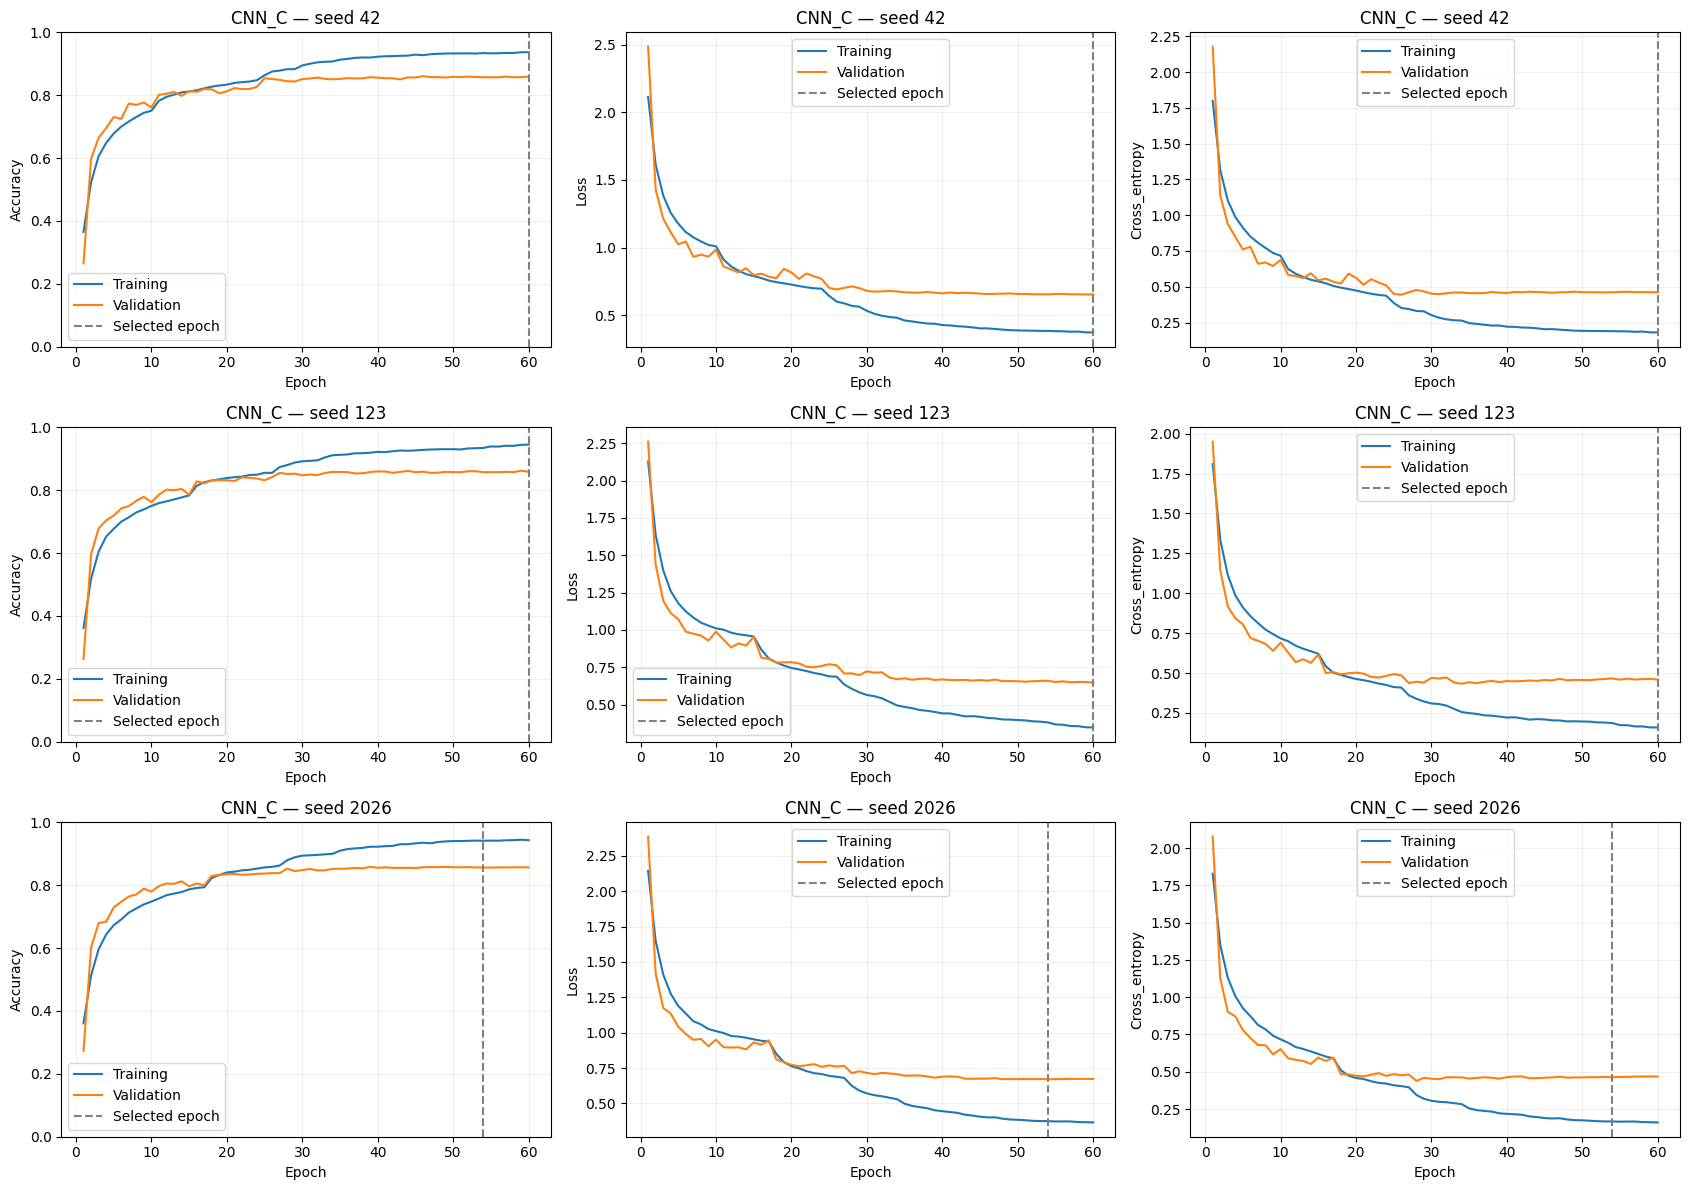

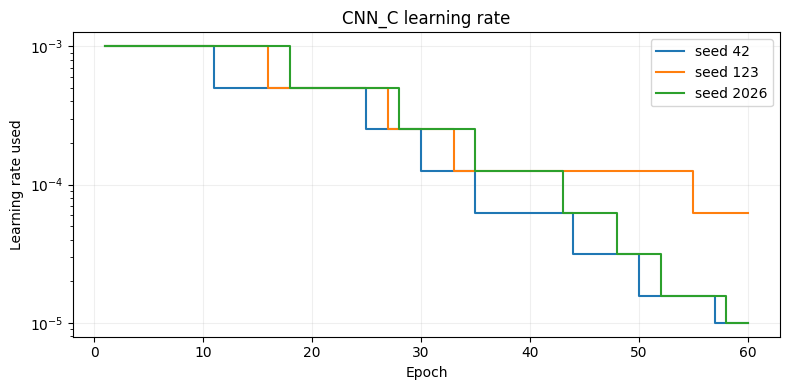

Saved experiment ZIP: /content/assignment3_results/CNN_ABC_C_spatial_dropout_step5_zero_one_20261119-001821/CNN_C.zip


In [52]:
all_results["CNN_C"], all_summaries["CNN_C"] = run_experiment("CNN_C")


## 8. 三模型汇总与统一下载
下表使用样本标准差（ddof=1）；准确率乘以 100 后为百分数。仅一个随机种子时标准差无法定义。
CNN_C 的 loss 包含 L2 惩罚项，不能直接与 A／B 的 loss 比较大小。
统一 ZIP 包含三个模型各自的输出及比较表。请下载后再结束 Colab 会话。


In [ ]:
required_models = ["CNN_A", "CNN_B", "CNN_C"]
missing = [name for name in required_models if name not in all_results]
assert not missing, f"请先完成这些模型的训练：{missing}"
combined_results = pd.concat([all_results[name] for name in required_models], ignore_index=True)
combined_results.to_csv(EXPERIMENT_DIR / "all_models_results_by_seed.csv", index=False)
comparison_metrics = ["parameters", "train_accuracy", "train_loss", "val_accuracy", "val_loss", "test_accuracy", "test_loss", "train_cross_entropy", "val_cross_entropy", "test_cross_entropy", "regularization_penalty", "train_val_accuracy_gap", "training_seconds", "seconds_per_epoch"]
comparison = combined_results.groupby("model", sort=False)[comparison_metrics].agg(["mean", "std"])
comparison.columns = [f"{metric}_{stat}" for metric, stat in comparison.columns]
comparison.to_csv(EXPERIMENT_DIR / "model_comparison.csv")
display(comparison)
if len(SEEDS) != 3:
    print("当前为快速检查，正式报告需要三个随机种子的结果。")

# 每个模型的 ZIP 已单独保存；统一 ZIP 排除这些重复归档，减少下载体积。
import zipfile
archive = str(EXPERIMENT_DIR) + ".zip"
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(EXPERIMENT_DIR.rglob("*")):
        if path.is_file() and path.suffix != ".zip":
            bundle.write(path, path.relative_to(EXPERIMENT_DIR))
print("三模型完整结果：", archive)


In [ ]:
# 下载包含三个模型结果及比较表的完整 ZIP。
from google.colab import files
files.download(archive)


## 报告检查清单 — CNN_A / CNN_B / CNN_C
- 说明模型结构、参数量、优化器、学习率、批次大小、归一化方式和训练轮数。
- 在对应模型的报告页面放入结构图和训练／验证曲线。
- 报告最终测试准确率，以及三个随机种子的均值与标准差，同时记录训练耗时和硬件。
- 说明权重选择规则，并根据实际结果分析过拟合情况。
- 给出 CNN_C 的手算参数量，区分可训练参数和不可训练参数。
- 仍需完成归一化对照实验及完整的六页报告。
